In [2]:
import sys
print("Python version:", sys.version)

import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nEnvironment check completed.")

Python version: 3.13.2 (tags/v3.13.2:4f8bb39, Feb  4 2025, 15:23:48) [MSC v.1942 64 bit (AMD64)]
Pandas: 2.2.3
NumPy: 2.2.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.6.1

Environment check completed.


In [3]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

# Download and load the public dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

# Rename the target for clarity
df.rename(
    columns={"MedHouseVal": "MedianHouseValue"},
    inplace=True
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 9)

First 5 rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedianHouseValue']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MedInc            20640 non-null  float64
 1   HouseAge          20640 non-null  float64
 2   AveRooms          20640 non-null  float64
 3   AveBedrms         20640 non-null  float64
 4   Population        20640 non-null  float64
 5   AveOccup          20640 non-null  float64
 6   Latitude          20640 non-null  float64
 7   Longitude         20640 non-null  float64
 8   MedianHouseValue  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00



Missing values per column:


MedInc              0
HouseAge            0
AveRooms            0
AveBedrms           0
Population          0
AveOccup            0
Latitude            0
Longitude           0
MedianHouseValue    0
dtype: int64


Duplicate rows: 0


In [5]:
# Check the dataset's quality

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

print("\nTarget variable summary:")
display(df["MedianHouseValue"].describe().to_frame())

Dataset shape: (20640, 9)
Duplicate rows: 0
Total missing values: 0

Missing values by column:


,Missing Values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedianHouseValue,0



Unique values per column:


,Unique Values
MedInc,12928
HouseAge,52
AveRooms,19392
AveBedrms,14233
Population,3888
AveOccup,18841
Latitude,862
Longitude,844
MedianHouseValue,3842



Target variable summary:


,MedianHouseValue
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


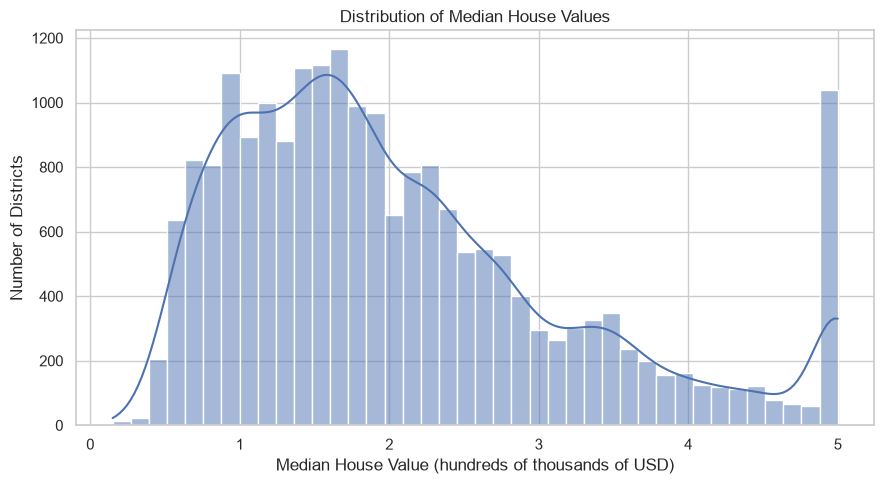

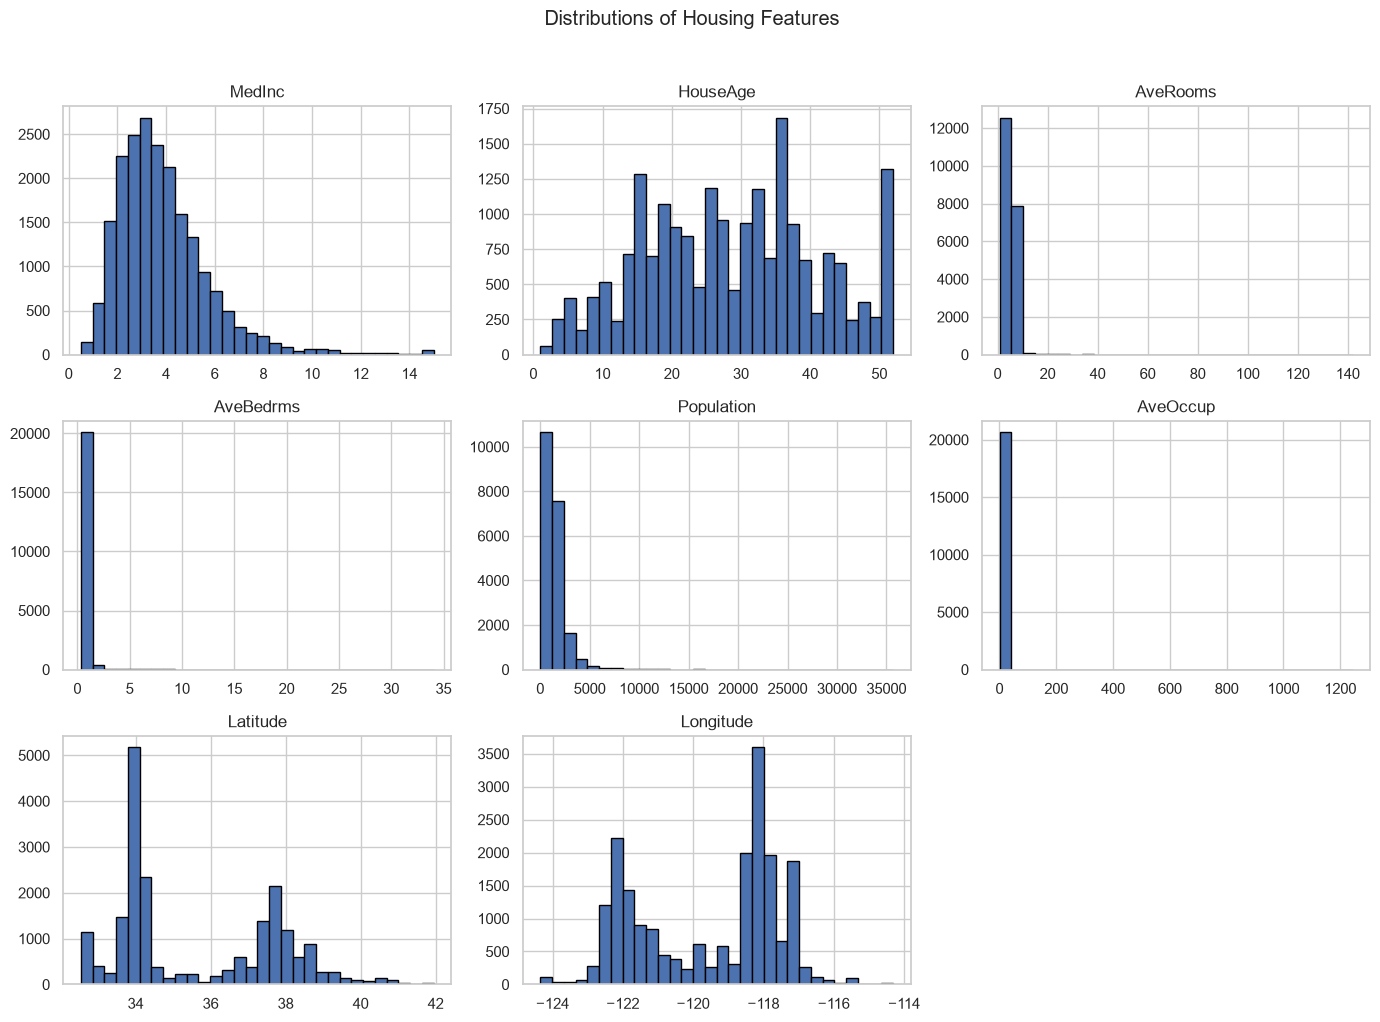

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Target distribution
plt.figure(figsize=(9, 5))
sns.histplot(df["MedianHouseValue"], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (hundreds of thousands of USD)")
plt.ylabel("Number of Districts")
plt.tight_layout()
plt.savefig("../screenshots/01_target_distribution.png", dpi=300)
plt.show()

# Feature distributions
df.drop(columns="MedianHouseValue").hist(
    figsize=(14, 10), bins=30, edgecolor="black"
)
plt.suptitle("Distributions of Housing Features", y=1.02)
plt.tight_layout()
plt.savefig("../screenshots/02_feature_distributions.png", dpi=300)
plt.show()

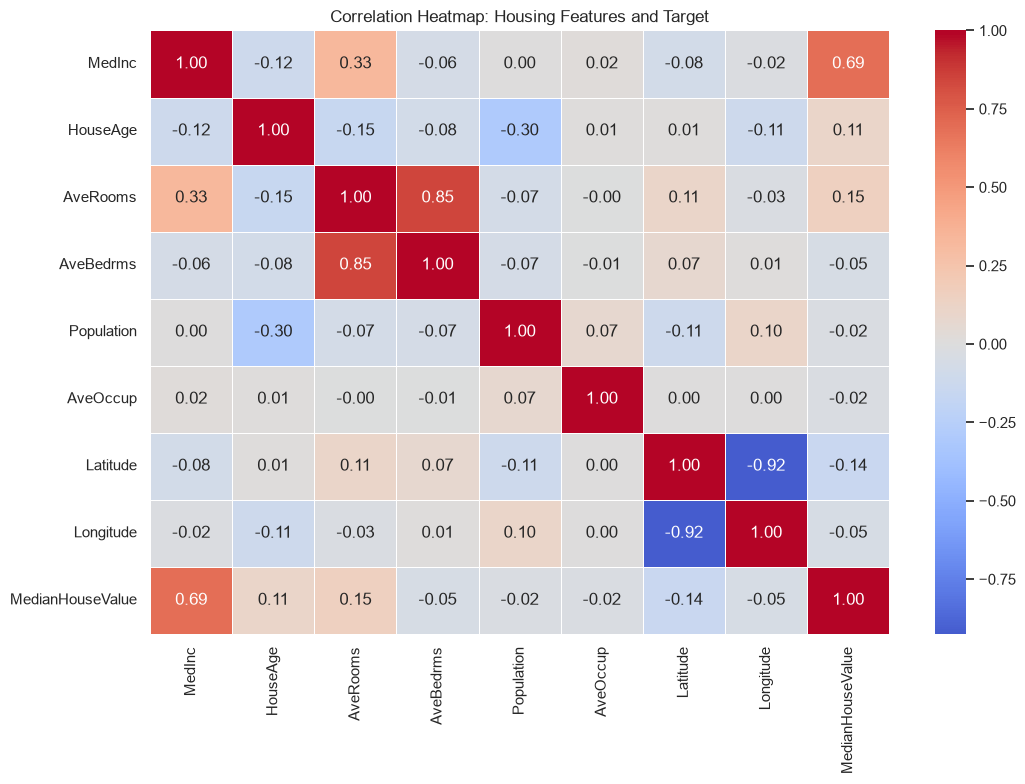

Feature correlations with the target:


,Correlation
MedInc,0.688
AveRooms,0.152
Latitude,-0.144
HouseAge,0.106
AveBedrms,-0.047
Longitude,-0.046
Population,-0.025
AveOccup,-0.024


In [7]:
# Correlation between all numerical variables
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Correlation Heatmap: Housing Features and Target")
plt.tight_layout()
plt.savefig("../screenshots/03_correlation_heatmap.png", dpi=300)
plt.show()

# Features most correlated with the target
target_corr = (
    correlation["MedianHouseValue"]
    .drop("MedianHouseValue")
    .sort_values(key=abs, ascending=False)
)

print("Feature correlations with the target:")
display(target_corr.to_frame("Correlation").round(3))

In [8]:
from sklearn.model_selection import train_test_split

# Input features
X = df.drop(columns=["MedianHouseValue"])

# Target variable
y = df["MedianHouseValue"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:", y.name)

Feature matrix shape: (20640, 8)
Target vector shape: (20640,)

Input features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target variable: MedianHouseValue


In [9]:
# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nTraining percentage:", round(len(X_train) / len(df) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(df) * 100, 2), "%")

Training features: (16512, 8)
Testing features: (4128, 8)
Training targets: (16512,)
Testing targets: (4128,)

Training percentage: 80.0 %
Testing percentage: 20.0 %


In [10]:
assert len(X_train) + len(X_test) == len(df)
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("All train/test split checks passed.")

All train/test split checks passed.


In [11]:
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.dummy import DummyRegressor

print("Model and evaluation imports completed.")

Model and evaluation imports completed.


In [12]:
models = {
    "Baseline (Mean)": DummyRegressor(strategy="mean"),

    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R2 Score": r2_score(y_test, predictions)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.3275,0.5053,0.8051
1,Gradient Boosting,0.3716,0.5422,0.7756
2,Ridge Regression,0.5332,0.7456,0.5758
3,Linear Regression,0.5332,0.7456,0.5758
4,Baseline (Mean),0.9061,1.1449,-0.0002


In [13]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import pandas as pd

cv_models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in cv_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=1,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Mean CV R2": scores["test_r2"].mean(),
        "Std CV R2": scores["test_r2"].std(),
        "Mean CV MAE": -scores["test_mae"].mean(),
        "Mean CV RMSE": -scores["test_rmse"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV RMSE"
).reset_index(drop=True)

display(cv_results_df.round(4))

,Model,Mean CV R2,Std CV R2,Mean CV MAE,Mean CV RMSE
0,Random Forest,0.8045,0.0061,0.3350,0.5111
1,Gradient Boosting,0.7881,0.0068,0.3698,0.5321
2,Linear Regression,0.6115,0.0124,0.5291,0.7205


In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold

# Smaller search for faster execution
param_distributions = {
    "n_estimators": [50, 100],
    "max_depth": [None, 15, 25],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, 0.8]
}

cv = KFold(n_splits=3, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=6,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:", random_search.best_params_)
print("Best CV RMSE:", round(-random_search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': 25}
Best CV RMSE: 0.5104


In [15]:
baseline_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

baseline_rf.fit(X_train, y_train)

baseline_cv_rmse = -cross_validate(
    baseline_rf,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)["test_score"].mean()

tuned_cv_rmse = -random_search.best_score_

print("Original Random Forest CV RMSE:", round(baseline_cv_rmse, 4))
print("Tuned Random Forest CV RMSE:", round(tuned_cv_rmse, 4))

if tuned_cv_rmse < baseline_cv_rmse:
    print("Tuning improved mean cross-validation RMSE.")
elif tuned_cv_rmse > baseline_cv_rmse:
    print("Tuning did not improve mean cross-validation RMSE.")
else:
    print("Both configurations have the same mean cross-validation RMSE.")

Original Random Forest CV RMSE: 0.5159
Tuned Random Forest CV RMSE: 0.5104
Tuning improved mean cross-validation RMSE.


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select the best tuned model
final_model = random_search.best_estimator_

# Train on the complete training dataset
final_model.fit(X_train, y_train)

# Predict test dataset
y_pred = final_model.predict(X_test)

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_test, y_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
final_r2 = r2_score(y_test, y_pred)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("MAE:", round(final_mae, 4))
print("RMSE:", round(final_rmse, 4))
print("R2 Score:", round(final_r2, 4))
print("R2 Percentage:", round(final_r2 * 100, 2), "%")

FINAL MODEL PERFORMANCE
-----------------------
MAE: 0.3263
RMSE: 0.5019
R2 Score: 0.8077
R2 Percentage: 80.77 %


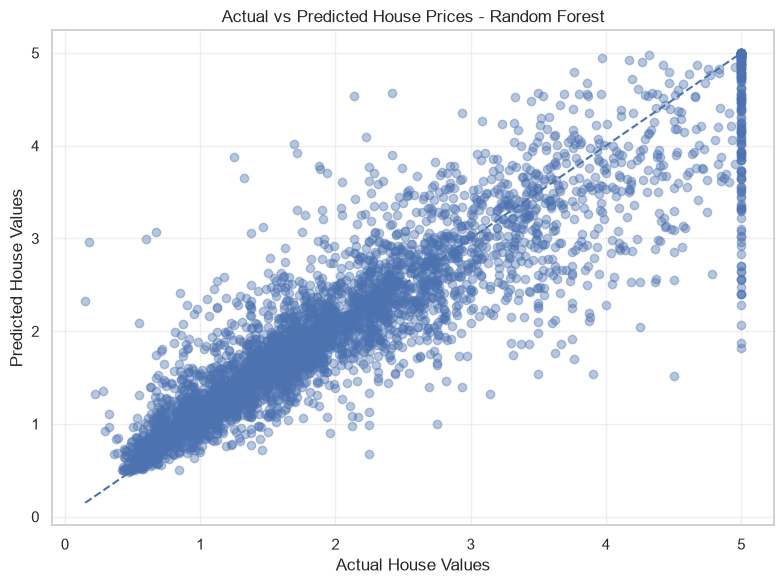

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Prices - Random Forest")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../screenshots/04_actual_vs_predicted.png", dpi=300)
plt.show()

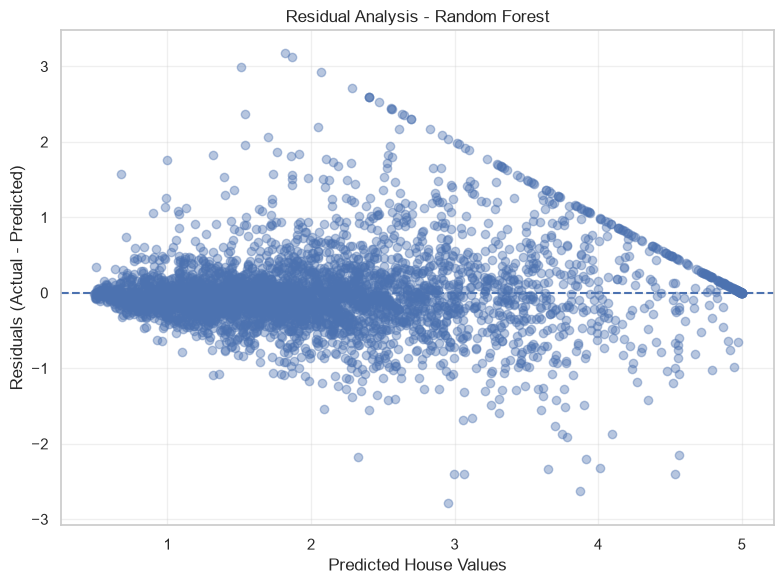

In [18]:
# Calculate residuals
residuals = y_test - y_pred

# Residual plot
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis - Random Forest")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../screenshots/05_residual_plot.png", dpi=300)
plt.show()

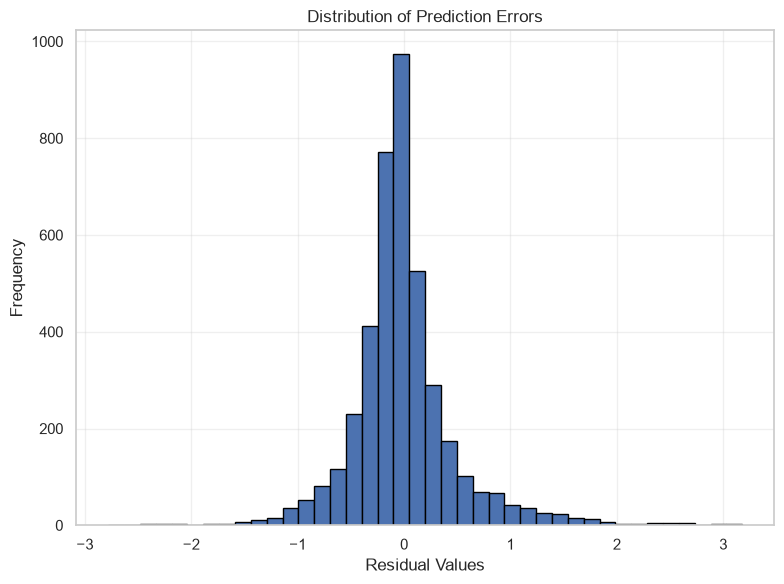

In [19]:
plt.figure(figsize=(8, 6))

plt.hist(residuals, bins=40, edgecolor="black")

plt.xlabel("Residual Values")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../screenshots/06_residual_distribution.png", dpi=300)
plt.show()

   Feature  Importance
    MedInc    0.479254
  AveOccup    0.134063
  Latitude    0.095136
 Longitude    0.093374
  AveRooms    0.080304
  HouseAge    0.056142
 AveBedrms    0.031387
Population    0.030340


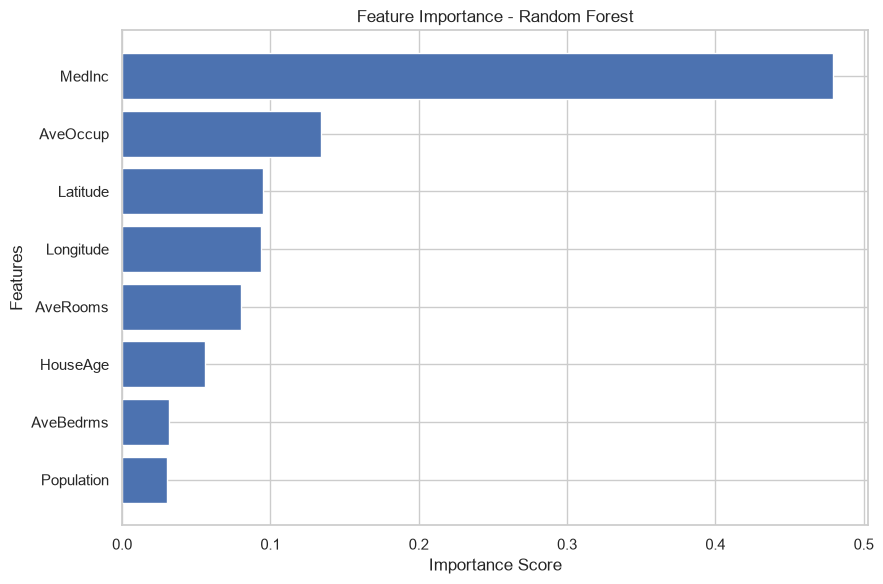

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.to_string(index=False))

# Visualize feature importance
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance - Random Forest")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("../screenshots/07_feature_importance.png", dpi=300)
plt.show()

In [21]:
import os
import joblib
import pandas as pd

# Create output folders if they do not exist
os.makedirs("../reports", exist_ok=True)
os.makedirs("../data", exist_ok=True)

# Save trained model
joblib.dump(
    final_model,
    "../reports/final_house_price_model.joblib"
)

# Save actual and predicted values
predictions_df = pd.DataFrame({
    "Actual_House_Value": y_test,
    "Predicted_House_Value": y_pred,
    "Residual": residuals
})

predictions_df.to_csv(
    "../data/house_price_predictions.csv",
    index=False
)

# Save evaluation metrics
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [final_mae, final_rmse, final_r2]
})

metrics_df.to_csv(
    "../reports/model_evaluation_metrics.csv",
    index=False
)

print("Model and output files saved successfully!")
print("1. final_house_price_model.joblib")
print("2. house_price_predictions.csv")
print("3. model_evaluation_metrics.csv")

Model and output files saved successfully!
1. final_house_price_model.joblib
2. house_price_predictions.csv
3. model_evaluation_metrics.csv
